Schritt 1: Beste Query Stategy für Logistic Regression finden: Eine informative und eine representative Based

In [27]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.datasets import make_moons
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import NearestNeighbors

from probly.evaluation.active_learning import (
    EntropySampling,
    LeastConfidentSampling,
    MarginSampling,
    RandomQuery,
    active_learning_steps,
    from_dataset,
)

In [28]:
SEED = 42
INITIAL_SIZE = 30
QUERY_SIZE = 20
N_ITERATIONS = 10

X, y = make_moons(n_samples=500, noise=0.2, random_state=SEED)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED, stratify=y)

Queer-by-Commitee:

In [29]:
class QueryByCommittee:
    """Select samples based on committee disagreement."""

    def __init__(self, committee_size=5, seed=42):
        self.committee_size = committee_size
        self.rng = np.random.default_rng(seed)

    def select(self, estimator, pool, n):

        X_labeled = pool.x_labeled
        y_labeled = pool.y_labeled
        X_unlabeled = pool.x_unlabeled

        votes = []

        for _ in range(self.committee_size):
            # Create a bootstrap sample
            while True:
                indices = self.rng.choice(len(X_labeled), size=len(X_labeled), replace=True)

                if len(np.unique(y_labeled[indices])) > 1:
                    break

            # Train committee member
            member = clone(estimator)

            member.fit(X_labeled[indices], y_labeled[indices])

            votes.append(member.predict(X_unlabeled))

        votes = np.array(votes)

        # Calculate voting probabilities (binary classification)
        p0 = np.mean(votes == 0, axis=0)
        p1 = np.mean(votes == 1, axis=0)

        # Calculate vote entropy
        disagreement = -(p0 * np.log(p0 + 1e-10) + p1 * np.log(p1 + 1e-10))

        # Select samples with highest disagreement
        return np.argsort(-disagreement, kind="stable")[:n]

K-Means:

In [30]:
class KMeansSampling:
    """Select representative samples from clusters."""

    def select(self, estimator, pool, n):

        X_pool = pool.x_unlabeled

        kmeans = KMeans(n_clusters=n, random_state=SEED, n_init=10)

        cluster_labels = kmeans.fit_predict(X_pool)

        selected = []

        for cluster_id in range(n):
            members = np.where(cluster_labels == cluster_id)[0]

            center = kmeans.cluster_centers_[cluster_id]

            distances = np.linalg.norm(X_pool[members] - center, axis=1)

            closest = members[np.argmin(distances)]

            selected.append(closest)

        return np.array(selected)

Density-Based:

In [31]:
class DensitySampling:
    """Select samples from high-density regions."""

    def select(self, estimator, pool, n):

        X_pool = pool.x_unlabeled

        neighbors = NearestNeighbors(n_neighbors=min(11, len(X_pool)))

        neighbors.fit(X_pool)

        distances, _ = neighbors.kneighbors(X_pool)

        # Exclude the distance to the point itself
        mean_distances = distances[:, 1:].mean(axis=1)

        # Select samples with highest density
        return np.argsort(mean_distances)[:n]

Query Stategies mit Lambda definieren

In [32]:
query_strategies = {
    "Random": lambda: RandomQuery(seed=SEED),
    "Margin": lambda: MarginSampling(),
    "Entropy": lambda: EntropySampling(),
    "Least Confidence": lambda: LeastConfidentSampling(),
    "Query-by-Committee": lambda: QueryByCommittee(committee_size=5, seed=SEED),
    "K-Means": lambda: KMeansSampling(),
    "Density-based": lambda: DensitySampling(),
}

information_based = ["Margin", "Entropy", "Least Confidence", "Query-by-Committee"]

representation_based = ["K-Means", "Density-based"]

Active-Learning:

In [33]:
def run_experiment(strategy):

    pool = from_dataset(X_train, y_train, X_test, y_test, initial_size=INITIAL_SIZE, seed=SEED)

    model = LogisticRegression(max_iter=1000, random_state=SEED)

    sizes = []
    accuracies = []

    for state in active_learning_steps(pool, model, strategy, query_size=QUERY_SIZE, n_iterations=N_ITERATIONS):
        prediction = state.estimator.predict(state.pool.x_test)

        accuracy = accuracy_score(state.pool.y_test, prediction)

        sizes.append(state.pool.n_labeled)
        accuracies.append(accuracy)

    return sizes, accuracies

In [34]:
results = {}

for name, create_strategy in query_strategies.items():
    print(f"Running {name}...")

    strategy = create_strategy()

    results[name] = run_experiment(strategy)

print("All experiments completed.")

Running Random...
Running Margin...
Running Entropy...
Running Least Confidence...


Running Query-by-Committee...
Running K-Means...
Running Density-based...
All experiments completed.


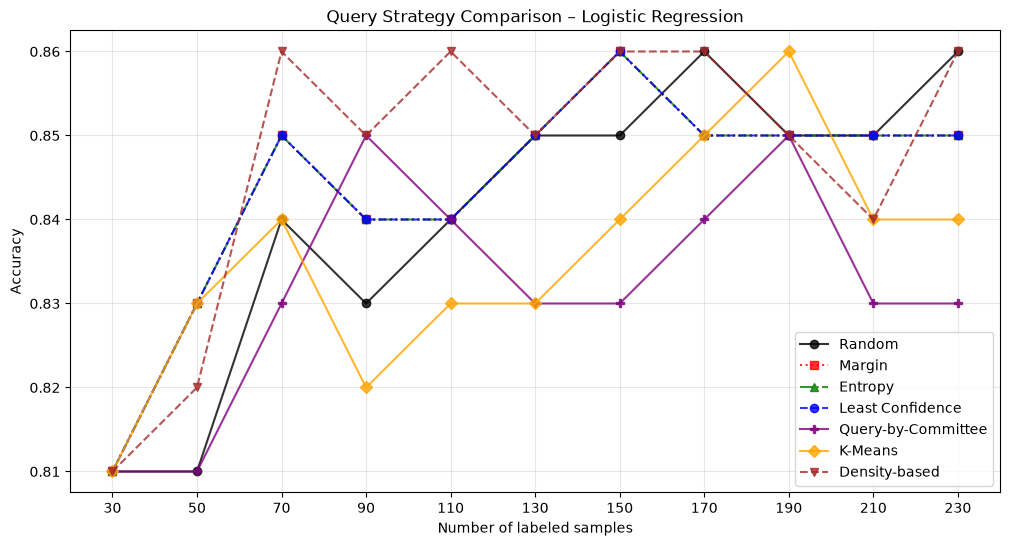

In [35]:
plt.figure(figsize=(12, 6))

styles = {
    "Random": ("black", "-", "o"),
    "Margin": ("red", ":", "s"),
    "Entropy": ("green", "-.", "^"),
    "Least Confidence": ("blue", "--", "o"),
    "Query-by-Committee": ("purple", "-", "P"),
    "K-Means": ("orange", "-", "D"),
    "Density-based": ("brown", "--", "v"),
}

for name, (sizes, accuracies) in results.items():
    color, linestyle, marker = styles[name]

    plt.plot(sizes, accuracies, label=name, color=color, linestyle=linestyle, marker=marker, markersize=6, alpha=0.8)

plt.xlabel("Number of labeled samples")
plt.ylabel("Accuracy")
plt.title("Query Strategy Comparison – Logistic Regression")
plt.xticks(range(30, 231, 20))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

AULC berechnen:

In [36]:
def calculate_aulc(sizes, accuracies):

    return np.trapezoid(accuracies, sizes) / (sizes[-1] - sizes[0])

In [37]:
summary = []

for name, (sizes, accuracies) in results.items():
    if name in information_based:
        category = "Information-based"

    elif name in representation_based:
        category = "Representation-based"

    else:
        category = "Baseline"

    summary.append(
        {
            "Strategy": name,
            "Category": category,
            "AULC": calculate_aulc(sizes, accuracies),
            "Final Accuracy": accuracies[-1],
        }
    )

summary_df = pd.DataFrame(summary)

display(summary_df.sort_values("AULC", ascending=False).round(4))

,Strategy,Category,AULC,Final Accuracy
6,Density-based,Representation-based,0.8485,0.86
2,Entropy,Information-based,0.8450,0.85
1,Margin,Information-based,0.8450,0.85
3,Least Confidence,Information-based,0.8450,0.85
0,Random,Baseline,0.8415,0.86
5,K-Means,Representation-based,0.8365,0.84
4,Query-by-Committee,Information-based,0.8330,0.83


In [38]:
best_information = max(information_based, key=lambda name: calculate_aulc(*results[name]))

best_representation = max(representation_based, key=lambda name: calculate_aulc(*results[name]))

print("Best Information-based Strategy:")
print(best_information)
print("AULC:", round(calculate_aulc(*results[best_information]), 4))

print("\nBest Representation-based Strategy:")
print(best_representation)
print("AULC:", round(calculate_aulc(*results[best_representation]), 4))

Best Information-based Strategy:
Margin
AULC: 0.845

Best Representation-based Strategy:
Density-based
AULC: 0.8485


Schritt 2: Bestimmung des optimalen Wechselzeitpunkts
Switching Strategy implementieren:

In [39]:
class SwitchingStrategy:
    """Switch from representation-based to information-based sampling."""

    def __init__(self, first, second, switch_at):

        self.first = first
        self.second = second
        self.switch_at = switch_at
        self.iteration = 0

    def select(self, estimator, pool, n):

        if self.iteration < self.switch_at:
            strategy = self.first

        else:
            strategy = self.second

        selected = strategy.select(estimator, pool, n)

        self.iteration += 1

        return selected

Alle möglichen Wechselzeitpunkte testen
testen der Wechselzeitpunkte 0 bis 10; Für jeden Wechselzeitpunkt wird ein vollständig neues Active-Learning-Experiment durchgeführt

In [40]:
switch_results = []
switch_curves = {}

for switch in range(N_ITERATIONS + 1):
    print(f"Testing switch at iteration {switch}...")

    strategy = SwitchingStrategy(
        first=query_strategies[best_representation](), second=query_strategies[best_information](), switch_at=switch
    )

    sizes, accuracies = run_experiment(strategy)

    switch_curves[switch] = (sizes, accuracies)

    switch_results.append(
        {
            "Switch": switch,
            "Labels at Switch": INITIAL_SIZE + switch * QUERY_SIZE,
            "AULC": calculate_aulc(sizes, accuracies),
            "Final Accuracy": accuracies[-1],
        }
    )

switch_df = pd.DataFrame(switch_results)

display(switch_df.sort_values("AULC", ascending=False).round(4))

Testing switch at iteration 0...
Testing switch at iteration 1...
Testing switch at iteration 2...
Testing switch at iteration 3...
Testing switch at iteration 4...
Testing switch at iteration 5...
Testing switch at iteration 6...
Testing switch at iteration 7...
Testing switch at iteration 8...
Testing switch at iteration 9...
Testing switch at iteration 10...


,Switch,Labels at Switch,AULC,Final Accuracy
8,8,190,0.8495,0.86
4,4,110,0.8490,0.85
7,7,170,0.8490,0.85
6,6,150,0.8490,0.85
5,5,130,0.8490,0.85
10,10,230,0.8485,0.86
9,9,210,0.8480,0.85
3,3,90,0.8470,0.85
2,2,70,0.8460,0.85
0,0,30,0.8450,0.85


Besten Wechselzeitpunkt zwischen 1 und 9 bestimmen:

In [41]:
actual_switches = switch_df[switch_df["Switch"].between(1, N_ITERATIONS - 1)]

best_row = actual_switches.loc[actual_switches["AULC"].idxmax()]

best_switch = int(best_row["Switch"])
best_aulc = best_row["AULC"]

print("Best strategy combination:")
print(best_representation, "->", best_information)

print("\nBest switching iteration:", best_switch)

print("Labels at switch:", INITIAL_SIZE + best_switch * QUERY_SIZE)

print("AULC:", round(best_aulc, 4))

print("Final Accuracy:", round(best_row["Final Accuracy"], 4))

Best strategy combination:
Density-based -> Margin

Best switching iteration: 8
Labels at switch: 190
AULC: 0.8495
Final Accuracy: 0.86


AULC:

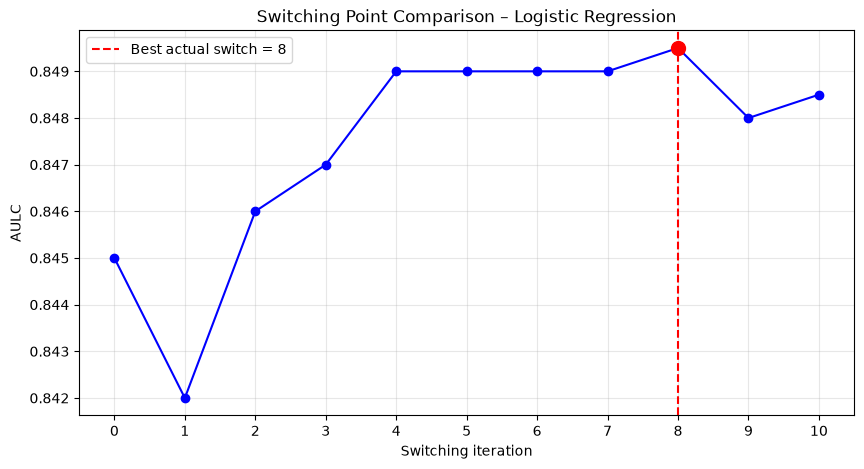

In [42]:
plt.figure(figsize=(10, 5))

plt.plot(switch_df["Switch"], switch_df["AULC"], color="blue", marker="o")

plt.axvline(best_switch, color="red", linestyle="--", label=f"Best actual switch = {best_switch}")

plt.scatter([best_switch], [best_aulc], color="red", s=100, zorder=5)

plt.xticks(range(N_ITERATIONS + 1))
plt.xlabel("Switching iteration")
plt.ylabel("AULC")
plt.title("Switching Point Comparison – Logistic Regression")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Switching vs Query Stategies:

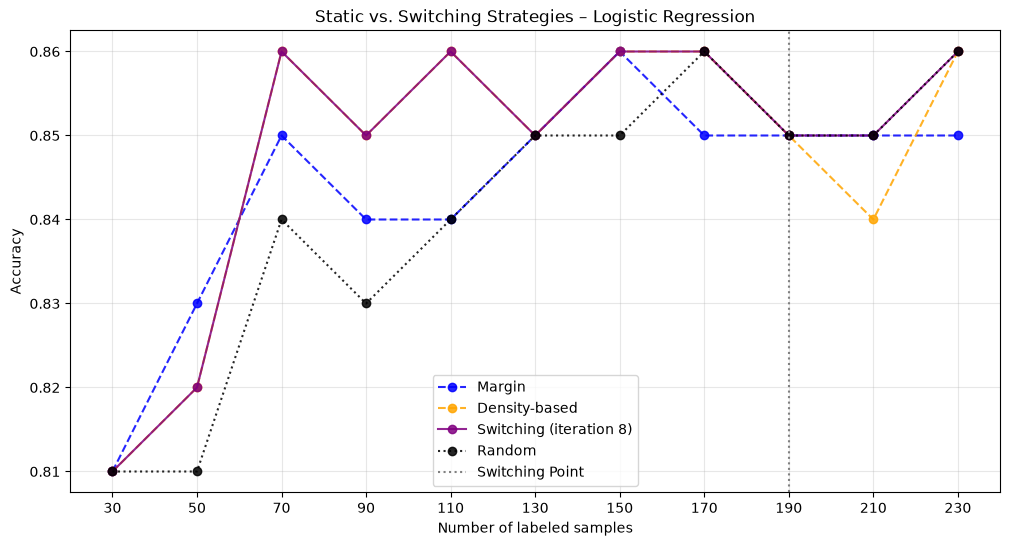

In [43]:
comparison = {
    best_information: results[best_information],
    best_representation: results[best_representation],
    f"Switching (iteration {best_switch})": switch_curves[best_switch],
    "Random": results["Random"],
}

plt.figure(figsize=(12, 6))

colors = ["blue", "orange", "purple", "black"]
linestyles = ["--", "--", "-", ":"]

for (name, (sizes, accuracies)), color, linestyle in zip(comparison.items(), colors, linestyles):
    plt.plot(sizes, accuracies, label=name, color=color, linestyle=linestyle, marker="o", markersize=6, alpha=0.85)

plt.axvline(INITIAL_SIZE + best_switch * QUERY_SIZE, color="grey", linestyle=":", label="Switching Point")

plt.xlabel("Number of labeled samples")
plt.ylabel("Accuracy")
plt.title("Static vs. Switching Strategies – Logistic Regression")
plt.xticks(range(30, 231, 20))
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [44]:
final_results = []

for name, (sizes, accuracies) in comparison.items():
    final_results.append(
        {"Strategy": name, "AULC": calculate_aulc(sizes, accuracies), "Final Accuracy": accuracies[-1]}
    )

final_df = pd.DataFrame(final_results)

display(final_df.sort_values("AULC", ascending=False).round(4))

,Strategy,AULC,Final Accuracy
2,Switching (iteration 8),0.8495,0.86
1,Density-based,0.8485,0.86
0,Margin,0.8450,0.85
3,Random,0.8415,0.86


Berechnung ob Switching sinnvoll:

In [45]:
information_aulc = calculate_aulc(*results[best_information])

representation_aulc = calculate_aulc(*results[best_representation])

random_aulc = calculate_aulc(*results["Random"])

best_static_aulc = max(information_aulc, representation_aulc)

improvement = best_aulc - best_static_aulc

print("Best Information-based:", best_information)
print("Best Representation-based:", best_representation)
print("Best switching iteration:", best_switch)

print("\nSwitching vs. Information:", round((best_aulc - information_aulc) * 100, 2), "percentage points")

print("Switching vs. Representation:", round((best_aulc - representation_aulc) * 100, 2), "percentage points")

print("Switching vs. Random:", round((best_aulc - random_aulc) * 100, 2), "percentage points")

print("\nImprovement over best selected static strategy:", round(improvement * 100, 2), "percentage points")

if improvement > 1e-10:
    print("Switching improves label efficiency.")

elif improvement < -1e-10:
    print("Static sampling performs better than switching.")

else:
    print("Switching provides no improvement.")

Best Information-based: Margin
Best Representation-based: Density-based
Best switching iteration: 8

Switching vs. Information: 0.45 percentage points
Switching vs. Representation: 0.1 percentage points
Switching vs. Random: 0.8 percentage points

Improvement over best selected static strategy: 0.1 percentage points
Switching improves label efficiency.
